In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("../src")

from ms_garch2_from_scratch import MSGARCH2
from ms_garch3_from_scratch import MSGARCH3

In [4]:
data = pd.read_csv(
    r"../data/processed/merged_data.csv"
)
data["Date"] = pd.to_datetime(data["Date"])
data = data.sort_values("Date").dropna(subset=["log_return"]).reset_index(drop=True)

print(data.shape)
data.tail(3)

(4022, 12)


,Date,log_return,NFCI,EPU,GPR,Yield_10Y,Yield_2Y,Spread_2Y10Y,VIX,EFFR,CPI_YoY,Unemployment
4019,2025-12-26,-0.000304,-0.537,289.0,130.955856,4.136,3.543,-0.593,13.60,3.64,2.653304,4.4
4020,2025-12-29,-0.003498,-0.537,289.0,130.955856,4.116,3.538,-0.578,14.20,3.64,2.653304,4.4
4021,2025-12-30,-0.001377,-0.537,289.0,130.955856,4.130,3.540,-0.590,14.33,3.64,2.653304,4.4


## MS-GARCH 2 régimes

In [5]:
model = MSGARCH2(
    returns=data["log_return"],
    dates=data["Date"],
    scale=100.0,
    demean=True
)

res = model.fit(n_starts=50, maxiter=2000, random_state=123, verbose=True)

start 01/50 | nll=5073.2090 | success=True
start 02/50 | nll=5073.2090 | success=True
start 03/50 | nll=5073.2090 | success=True
start 04/50 | nll=5073.2090 | success=True
start 05/50 | nll=5073.2090 | success=True
start 06/50 | nll=5073.2090 | success=True
start 07/50 | nll=5073.2090 | success=True
start 08/50 | nll=5073.2090 | success=True
start 09/50 | nll=5073.2090 | success=True
start 10/50 | nll=5073.2090 | success=True
start 11/50 | nll=5073.2090 | success=True
start 12/50 | nll=5073.2090 | success=True
start 13/50 | nll=5073.2090 | success=True
start 14/50 | nll=5073.2090 | success=True
start 15/50 | nll=5073.2090 | success=True
start 16/50 | nll=5073.2090 | success=True
start 17/50 | nll=5073.2090 | success=True
start 18/50 | nll=5073.2090 | success=True
start 19/50 | nll=5073.2090 | success=True
start 20/50 | nll=5073.2090 | success=True
start 21/50 | nll=5073.2090 | success=True
start 22/50 | nll=5073.2090 | success=True
start 23/50 | nll=5073.2091 | success=True
start 24/50

In [6]:
model.summary()

MS-GARCH(2)  nobs=4022  loglik=-5073.21  AIC=10162.42  BIC=10212.81
  success=True
  Regime 1: omega=0.00689  alpha=0.0988  beta=0.8563  unc_var=0.15324
  Regime 2: omega=0.36044  alpha=0.3177  beta=0.6739  unc_var=42.79073
  p11=0.8311  p22=0.2119


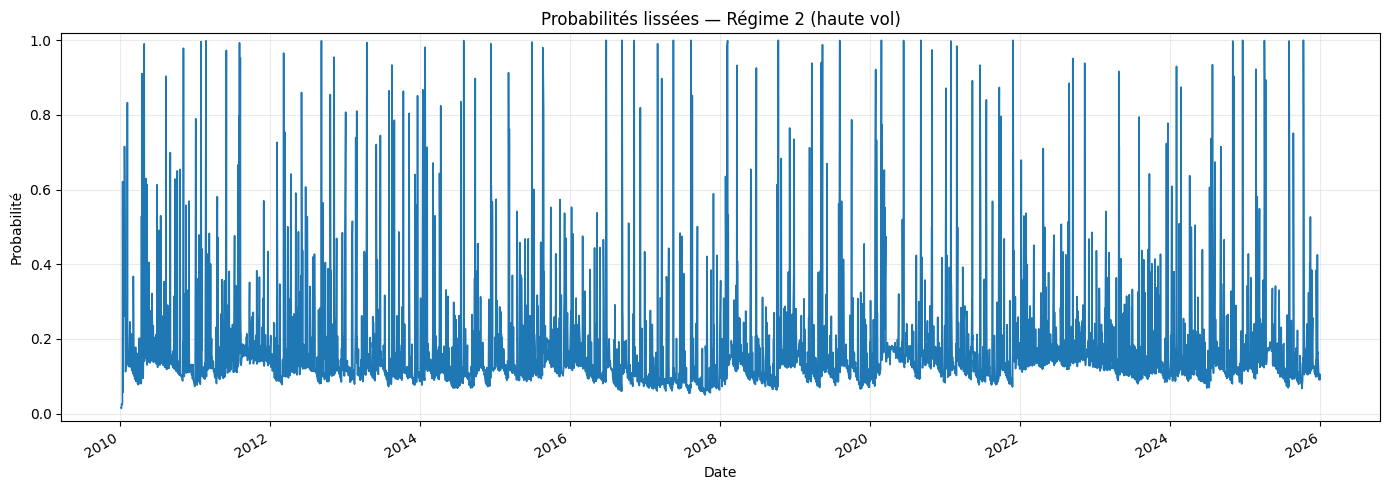

In [7]:
ax = model.plot_regime_probabilities(
    start="2010-01-01",
    end="2025-12-31",
    which="smoothed"
)

In [8]:
# vérif que les grandes crises sont bien capturées en régime 2
probs = res["smoothed_probs"].copy()
print("Moyenne P(régime 2) en 2020 (covid):")
print(probs.loc["2020-01-01":"2020-12-31", "Regime_2"].mean().round(3))
print("Moyenne P(régime 2) en 2011 (crise dette EU):")
print(probs.loc["2011-01-01":"2011-12-31", "Regime_2"].mean().round(3))

Moyenne P(régime 2) en 2020 (covid):
0.194
Moyenne P(régime 2) en 2011 (crise dette EU):
0.194


In [9]:
probs_export = pd.concat([
    res["filtered_probs"].rename(columns=lambda c: "filtered_" + c),
    res["predicted_probs"].rename(columns=lambda c: "predicted_" + c),
    res["smoothed_probs"].rename(columns=lambda c: "smoothed_" + c),
    res["variances"],
], axis=1)

probs_export.to_csv("../results/ms_garch2_probabilities.csv")
print("Sauvegardé : ms_garch2_probabilities.csv")

Sauvegardé : ms_garch2_probabilities.csv


## MS-GARCH 3 régimes

On tourne avec moins de starts parce que c'est long (15 paramètres).

In [10]:
model3 = MSGARCH3(
    returns=data["log_return"],
    dates=data["Date"],
    scale=100.0,
    demean=True
)

# moins de starts que pour le 2-régimes, sinon ça tourne trop longtemps
res3 = model3.fit(n_starts=30, maxiter=200, random_state=42, verbose=True)

start 01/30 | nll=5056.8875 | success=True
start 02/30 | nll=5056.8877 | success=True
start 03/30 | nll=5056.8883 | success=True
start 04/30 | nll=5056.8873 | success=True
start 05/30 | nll=5056.8886 | success=True
start 06/30 | nll=5044.1473 | success=True
start 07/30 | nll=5056.8877 | success=True
start 08/30 | nll=5044.1434 | success=True
start 09/30 | nll=5056.8886 | success=True
start 10/30 | nll=5058.9858 | success=True
start 11/30 | nll=5044.1433 | success=True
start 12/30 | nll=5044.1499 | success=True
start 13/30 | nll=5044.1476 | success=True
start 14/30 | nll=5044.1438 | success=True
start 15/30 | nll=5044.1440 | success=True
start 16/30 | nll=5044.1434 | success=True
start 17/30 | nll=5044.1438 | success=True
start 18/30 | nll=5056.8897 | success=True
start 19/30 | nll=5066.6038 | success=True
start 20/30 | nll=5056.8873 | success=True
start 21/30 | nll=5044.4684 | success=True
start 22/30 | nll=5044.1447 | success=True
start 23/30 | nll=5056.8942 | success=True
start 24/30

In [11]:
model3.summary()

MS-GARCH(3)  nobs=4022  loglik=-5044.14  AIC=10118.29  BIC=10212.78
  success=True
  Regime 1: omega=0.00000  alpha=0.0511  beta=0.6663  unc_var=0.00000
  Regime 2: omega=0.01333  alpha=0.1413  beta=0.8432  unc_var=0.85974
  Regime 3: omega=0.56695  alpha=0.3482  beta=0.6463  unc_var=103.02154
Matrice de transition:
          To_1    To_2    To_3
From_1  0.0000  0.9023  0.0977
From_2  0.1510  0.7755  0.0735
From_3  0.4788  0.2917  0.2295


In [12]:
# matrice de transition estimée
res3["transition_matrix"]

,To_1,To_2,To_3
From_1,5.153845e-10,0.902255,0.097745
From_2,1.510018e-01,0.775455,0.073543
From_3,4.787637e-01,0.291722,0.229515


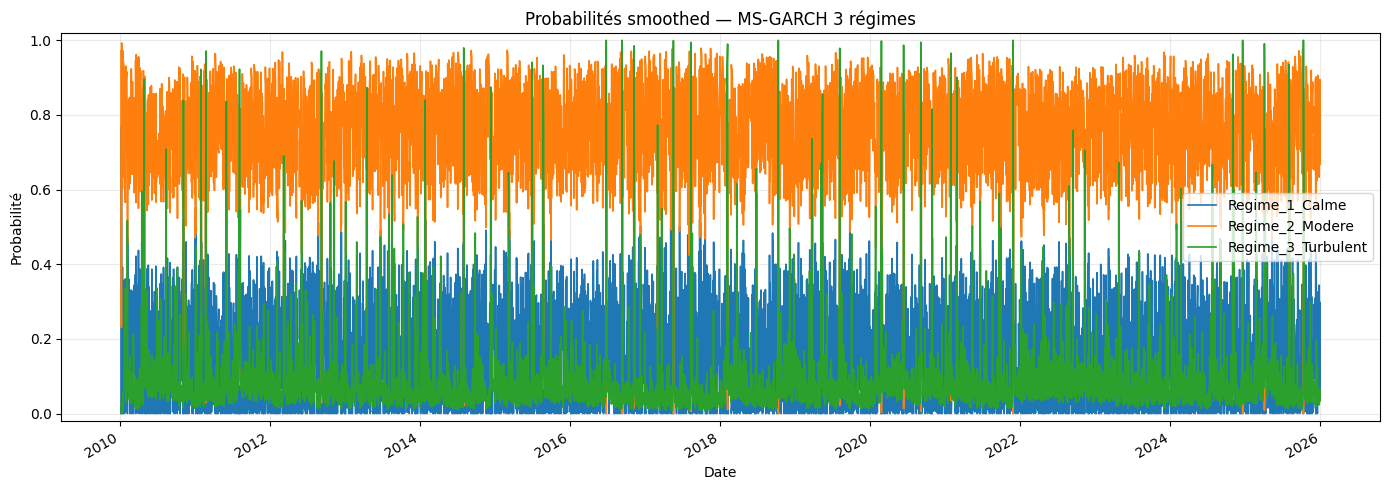

In [13]:
ax3 = model3.plot_regime_probabilities(
    start="2010-01-01",
    end="2025-12-31",
    which="smoothed"
)

In [14]:
probs3_export = pd.concat([
    res3["filtered_probs"].rename(columns=lambda c: "filtered_" + c),
    res3["predicted_probs"].rename(columns=lambda c: "predicted_" + c),
    res3["smoothed_probs"].rename(columns=lambda c: "smoothed_" + c),
    res3["variances"],
], axis=1)

probs3_export.to_csv("../results/ms_garch3_probabilities.csv")
print("Sauvegardé : ms_garch3_probabilities.csv")

Sauvegardé : ms_garch3_probabilities.csv


In [15]:
print(f"MS-GARCH(2)  AIC={res['aic']:.2f}  BIC={res['bic']:.2f}  loglik={res['loglik']:.2f}")
print(f"MS-GARCH(3)  AIC={res3['aic']:.2f}  BIC={res3['bic']:.2f}  loglik={res3['loglik']:.2f}")

MS-GARCH(2)  AIC=10162.42  BIC=10212.81  loglik=-5073.21
MS-GARCH(3)  AIC=10118.29  BIC=10212.78  loglik=-5044.14
